#### Step 1: Map the problem to circuit & operators 

In [12]:
# import the necessary libraries
  
from qiskit import QuantumCircuit

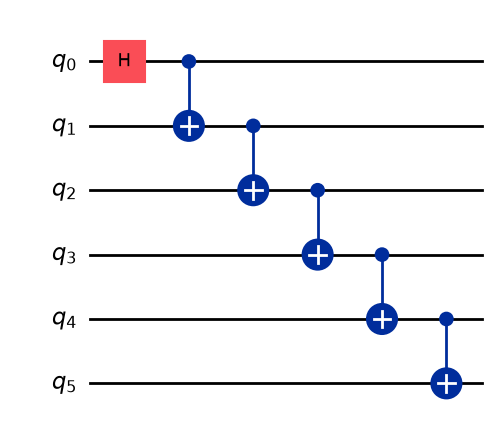

In [13]:
def get_qc_for_n_qubit_GHZ_state(n):
    qc = QuantumCircuit(n)
    qc.h(0)
    for i in range(n-1):
        qc.cx(i, i+1)
    return qc

n = 6
qc = get_qc_for_n_qubit_GHZ_state(n) 
qc.draw(output='mpl')

In [14]:
from qiskit.quantum_info import SparsePauliOp

operator_strings = ['Z' + 'I' * i + 'Z' + 'I' * (n-2-i) for i in range(n-1)]
print(operator_strings)
print(len(operator_strings))

operators = [SparsePauliOp(operator_strings) for operator_strings in operator_strings]
print(operators)

['ZZIIII', 'ZIZIII', 'ZIIZII', 'ZIIIZI', 'ZIIIIZ']
5
[SparsePauliOp(['ZZIIII'],
              coeffs=[1.+0.j]), SparsePauliOp(['ZIZIII'],
              coeffs=[1.+0.j]), SparsePauliOp(['ZIIZII'],
              coeffs=[1.+0.j]), SparsePauliOp(['ZIIIZI'],
              coeffs=[1.+0.j]), SparsePauliOp(['ZIIIIZ'],
              coeffs=[1.+0.j])]


#### Step 2: Optimize the Quantum circuit

#### Step 3: Execute on the backend

In [15]:
from qiskit_aer.primitives import Estimator

estimator = Estimator()
job = estimator.run([qc] * len(operators), operators)
job.result()


EstimatorResult(values=array([1., 1., 1., 1., 1.]), metadata=[{'shots': 1024, 'variance': 0.0, 'simulator_metadata': [{'num_bind_params': 1, 'runtime_parameter_bind': False, 'parallel_state_update': 8, 'parallel_shots': 1, 'sample_measure_time': 0.001291542, 'noise': 'ideal', 'batched_shots_optimization': False, 'remapped_qubits': False, 'active_input_qubits': [0, 1, 2, 3, 4, 5], 'device': 'CPU', 'time_taken': 0.001554667, 'measure_sampling': True, 'num_clbits': 6, 'max_memory_mb': 16384, 'input_qubit_map': [[5, 5], [4, 4], [3, 3], [2, 2], [1, 1], [0, 0]], 'num_qubits': 6, 'method': 'stabilizer', 'required_memory_mb': 0, 'fusion': {'enabled': False}}]}, {'shots': 1024, 'variance': 0.0, 'simulator_metadata': [{'num_bind_params': 1, 'runtime_parameter_bind': False, 'parallel_state_update': 8, 'parallel_shots': 1, 'sample_measure_time': 0.001291542, 'noise': 'ideal', 'batched_shots_optimization': False, 'remapped_qubits': False, 'active_input_qubits': [0, 1, 2, 3, 4, 5], 'device': 'CPU', 

#### Step 4: Post process and plotting the results

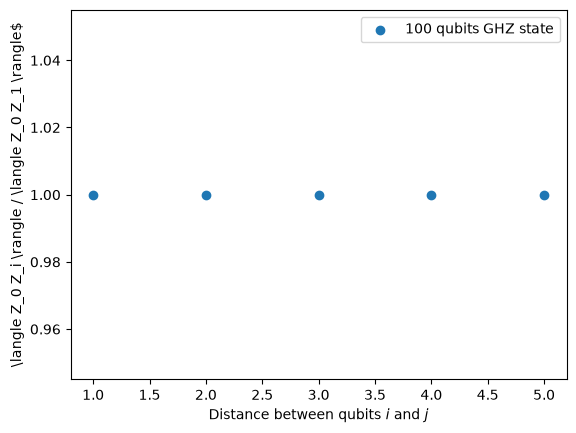

In [16]:
import matplotlib.pyplot as plt

data = list(range(1, len(operators) + 1))
result = job.result()
values = result.values
values = [v / values[0] for v in values]

plt.scatter(data, values, marker='o', label='100 qubits GHZ state')
plt.xlabel('Distance between qubits $i$ and $j$')
plt.ylabel(r'\langle Z_0 Z_i \rangle / \langle Z_0 Z_1 \rangle$')
plt.legend()
plt.show()